# Homework: Multimodal Models - Image Captioning and Visual Question Answering

**Goal**

In this assignment, you will experiment with multimodal models that combine vision and language.

You will use a pretrained model to:

1. Generate a caption for an image.
2. Answer questions about an image.

You will also analyze the model's strengths, weaknesses, and possible failure cases.

## Task 1 - Image Captioning (30 Points)

**Description**

Given an input image, use a pretrained multimodal model to generate a textual description of the image.

Example:

**Input**: An image of a dog running in a park.

**Output**: A dog is running on grass in a park.

**Requirements**

Use at least 5 different images.

The images should include:

* At least one image with people
* At least one image with animals
* At least one indoor scene
* At least one outdoor scene
* At least one image with multiple objects

You may use your own images or images from an open dataset.

**Suggested Models**

You may use one of the following:

* Salesforce/blip-image-captioning-base
* Salesforce/blip-image-captioning-large
* microsoft/git-base
* Any other image-captioning model from HuggingFace

**Deliverables**

1. Present your images and model captions clearly

    Display each image together with the caption generated by the model.

2. Analyze model failures

    Choose at least 2 examples where the model made a mistake or gave an incomplete caption.

    For each example, explain:

    * What the model predicted
    * What the correct description should be
    * Why the model may have failed

    For example :

    "The model described the image as “a person sitting at a table,” but it missed the laptop and the coffee cup.
    This may have happened because the person was the most visually dominant object, while the smaller objects were less noticeable."


In [1]:
import torch
from transformers import BlipProcessor, BlipForConditionalGeneration
from PIL import Image
import matplotlib.pyplot as plt
import os

# Load the processor and model
processor = BlipProcessor.from_pretrained('Salesforce/blip-image-captioning-base')
model = BlipForConditionalGeneration.from_pretrained('Salesforce/blip-image-captioning-base')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

In [2]:

# Images live in ../images (people, outdoor, animals, objects, indoor)
IMAGE_DIR = '../images'
image_paths = [os.path.join(IMAGE_DIR, f) for f in sorted(os.listdir(IMAGE_DIR)) if os.path.isfile(os.path.join(IMAGE_DIR, f))]

def generate_caption(image_path):
    raw_image = Image.open(image_path).convert('RGB')
    inputs = processor(raw_image, return_tensors='pt')
    out = model.generate(**inputs)
    caption = processor.decode(out[0], skip_special_tokens=True)
    return raw_image, caption

# Process and display all found files stacked vertically
n = len(image_paths)
if n > 0:
    fig, axes = plt.subplots(n, 1, figsize=(10, 7 * n))
    # Ensure axes is an array even if n=1
    if n == 1: axes = [axes]

    for i, path in enumerate(image_paths):
        img, cap = generate_caption(path)
        axes[i].imshow(img)
        axes[i].set_title(f'File: {os.path.basename(path)}\nCaption: {cap}', fontsize=12, pad=15)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f'No files found in {IMAGE_DIR}.')

No files found in /content/.


## Mistake analysis
### A room with a yellow couch and a blue rug
The couch is pink/beige and the yellow part was confused with the yellow hutch. Lots of objects are missing from the description. The model failed since it confused between furnitures and was not set to the right verbosity.

### a group of birds standing on top of a dirt field
This is actually grass, not a dirt field. The model probably failed since the grass is mixed with some dirt

## Task 2 - Visual Question Answering (30 points)

**Description**

Given an image and a natural-language question, use a pretrained multimodal model to answer the question.

Example:

**Input image**: A kitchen scene

**Question**: How many chairs are visible?

**Output**: Four.

**Requirements**

Use at least 3 images.

For each image, ask at least 3 questions.

Your questions should include:

* One object-recognition question
* One counting question
* One color or attribute question

Example questions:
* What animal is in the image?
* How many people are visible?
* What color is the car?

**Suggested Models**

You may use:

* Salesforce/blip-vqa-base
* Salesforce/blip-vqa-capfilt-large
* Any other VQA model from HuggingFace

**Deliverables**

1. Present your images, questions and model's answers clearly

    Display each image together with the Q&A generated by the model.

2. Analyze model failures

    Choose at least 2 examples where the model made a mistake or gave an incomplete caption.

    For each example, explain:

    * What the model predicted
    * What the correct description should be
    * Why the model may have failed

    **You are required to find examples where it fails and analyse why**


In [3]:
import torch
from transformers import BlipProcessor, BlipForQuestionAnswering
from PIL import Image
import matplotlib.pyplot as plt

# Load the VQA model and processor
vqa_model_name = 'Salesforce/blip-vqa-capfilt-large'
vqa_processor = BlipProcessor.from_pretrained(vqa_model_name)
vqa_model = BlipForQuestionAnswering.from_pretrained(vqa_model_name)


model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/524 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.54G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.54G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/789 [00:00<?, ?it/s]

In [4]:
def ask_question(image_path, question):
    raw_image = Image.open(image_path).convert('RGB')
    inputs = vqa_processor(raw_image, question, return_tensors='pt')
    out = vqa_model.generate(**inputs)
    answer = vqa_processor.decode(out[0], skip_special_tokens=True)
    return answer

# Map specific questions to each of the 5 images available
vqa_mapping = {
    'people.jpg': [
        'What are the people sitting on?',
        'How many people are there?',
        'What color are the shirts?'
    ],
    'outdoor.jpg': [
        'What activity are they doing?',
        'How many bicycles are visible?',
        'What color is the sky?'
    ],
    'animals.webp': [
        'What kind of animals are these?',
        'How many birds are there?',
        'What color is the ground?'
    ],
    'objects.webp': [
        'What is on the table?',
        'How many objects are there?',
        'What color is the largest object?'
    ],
    'indoor.webp': [
        'What furniture is in the room?',
        'How many pillows are on the couch?',
        'What color is the rug?'
    ]
}

# Display results for all images in image_paths
for path in image_paths:
    filename = os.path.basename(path)
    if filename in vqa_mapping:
        img = Image.open(path)
        plt.figure(figsize=(6, 4))
        plt.imshow(img)
        plt.title(f"Image: {filename}")
        plt.axis('off')
        plt.show()

        print(f"--- Results for {filename} ---")
        for q in vqa_mapping[filename]:
            ans = ask_question(path, q)
            print(f"Q: {q}\nA: {ans}\n")

## Task 2 - VQA Failure Analysis

### 3. animals.webp
**Question**: How many birds are ther?

**Model Prediction**: 6

**Correct Description**: 4

**Analysis**: Some birds are obstruct each other

### 4. objects.webp
**Question**: What is on the table?

**Model Prediction**: toys

**Correct Description**: A collection of stationary and electronics.

**Analysis**: This messy configuration of objects can really look like a box of toys


## Task 3 - Personalized Face Recognition with a Celebrity Dataset (40 points)


**Goal**

Build a small personalized multimodal recognition system.

For this task, you will use a public celebrity face dataset rather than private photos of family or friends.

Although the same approach could easily be adapted to recognize your own friends, family members, or personal image collections, in this assignment you must use a celebrity dataset in order to avoid privacy concerns and to ensure a consistent evaluation setting across all students.

Students who are interested may later explore how the same techniques can be extended to build personalized multimodal recognition systems for recreational or educational purposes outside the scope of this course.

The system should learn to recognize a small set of known identities and answer questions such as:

* Who is in the image?
* Is this person Emma Watson or Leonardo DiCaprio?
* What is Emma doing or wearing?

1. Choose 3-5 identities from a celebrity dataset. For each identity, collect at least 8 images.

2. split the images into:
   * Train/reference set: 5-6 images per identity
   * Test/query set: 2-3 images per identity

3. Use a pretrained model to convert each image into an embedding vector. Recommended model : CLIP

4. Compare a query image to the known identity images using cosine similarity

5. Use the predicted identity to answer simple personalized questions.

    Note:

    CLIP similarity predicts who the person is; a VQA/captioning model answers visual attribute/action questions about the image.

    Use this structure:
    1. CLIP similarity → Who is this?
    2. VQA model → What is the person wearing / doing / holding?
    3. Combined answer → “This is probably Emma Watson. She appears to be wearing a black dress.”

              Example:

              Question: Who is in the image?

              Answer: This is probably Emma Watson.

              Question: Is this Barack Obama?

              Answer: No, this is probably Taylor Swift.

              Question: What is Emma wearing?

              Answer: The model appears to show Emma wearing a black jacket.

6. Analyze when the system works and when it fails. Show images , Q&A and disscuess results.

In [6]:
import numpy as np
import torch
import os
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt
from transformers import CLIPVisionModelWithProjection, AutoImageProcessor

vision_model_name = 'openai/clip-vit-base-patch32'
image_processor = AutoImageProcessor.from_pretrained(vision_model_name)
vision_model = CLIPVisionModelWithProjection.from_pretrained(vision_model_name)

def get_image_embedding(image_array):
    image_array = np.stack([image_array] * 3, axis=-1)
    image = Image.fromarray((image_array * 255).astype('uint8'))
    inputs = image_processor(images=image, return_tensors='pt')
    with torch.no_grad():
        outputs = vision_model(**inputs)
    image_features = outputs.image_embeds
    return image_features.cpu().numpy().flatten()

print("Loading LFW dataset...")
lfw_people = fetch_lfw_people(min_faces_per_person=20, resize=0.5)
X = lfw_people.data
y = lfw_people.target
target_names = lfw_people.target_names

selected_people = list(target_names[:3])
selected_indices = [i for i in range(len(y)) if target_names[y[i]] in selected_people]
selected_images = X[selected_indices]
selected_labels = y[selected_indices]

train_embeddings = {}
test_images = {}

for person_id, person_name in enumerate(selected_people):
    person_images = [selected_images[i] for i in range(len(selected_images)) if selected_labels[i] == person_id]

    if len(person_images) >= 5:
        train_count = max(5, len(person_images) - 2)
        train_imgs = person_images[:train_count]
        test_imgs = person_images[train_count:]

        train_embs = [get_image_embedding(img) for img in train_imgs]
        train_embeddings[person_name] = np.array(train_embs)
        test_images[person_name] = test_imgs
        print(f"{person_name}: {len(train_imgs)} training, {len(test_imgs)} testing")

dataset_found = len(train_embeddings) > 0

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0

Loading LFW dataset...


[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assi

Alejandro Toledo: 37 training, 2 testing


[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assi

Alvaro Uribe: 33 training, 2 testing


[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assi

Amelie Mauresmo: 19 training, 2 testing


[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


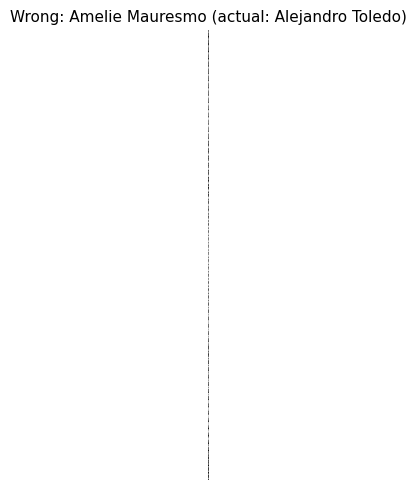

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


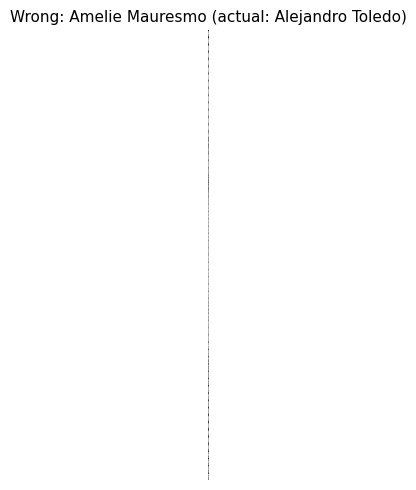

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


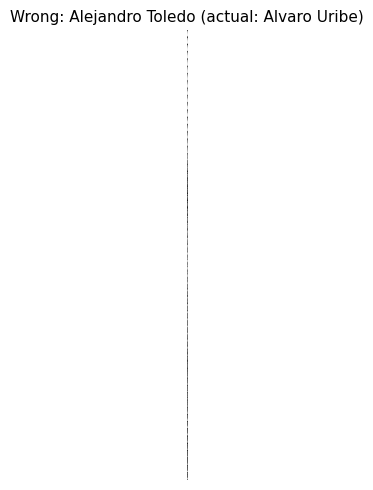

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


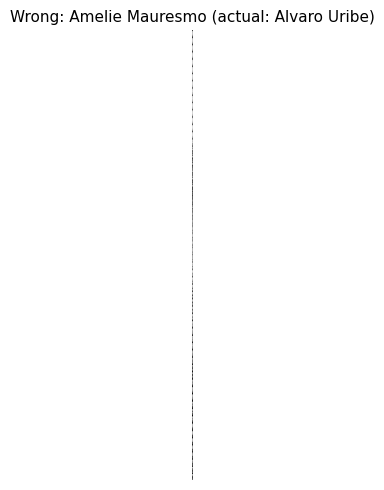

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


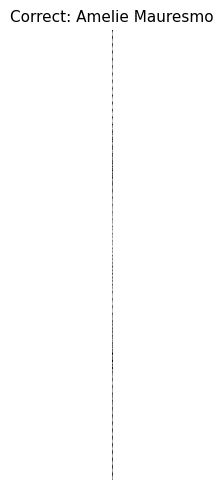

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


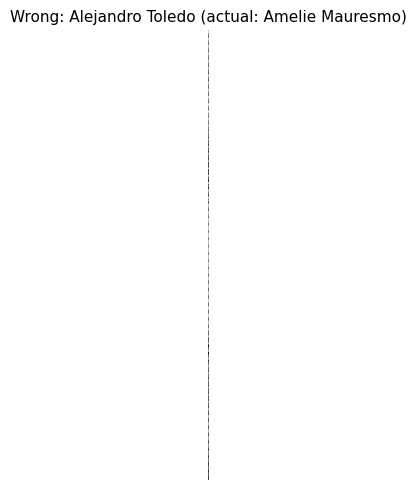

Accuracy: 17%


In [8]:
def predict_identity(image_array, train_embeddings, threshold=0.5):
    query_embedding = get_image_embedding(image_array)
    best_match = None
    best_similarity = -1
    similarities = {}

    for celebrity, embeddings in train_embeddings.items():
        sims = cosine_similarity([query_embedding], embeddings)[0]
        avg_similarity = np.mean(sims)
        similarities[celebrity] = avg_similarity

        if avg_similarity > best_similarity:
            best_similarity = avg_similarity
            best_match = celebrity

    if best_similarity < threshold:
        return "Unknown", best_similarity, similarities
    return best_match, best_similarity, similarities

if dataset_found:
    test_results = []
    for celebrity, test_image_arrays in test_images.items():
        for test_img in test_image_arrays:
            predicted, similarity, _ = predict_identity(test_img, train_embeddings)

            fig, ax = plt.subplots(figsize=(6, 5))
            img_rgb = np.stack([test_img] * 3, axis=-1)
            ax.imshow(img_rgb, cmap='gray')

            correct = predicted == celebrity
            title = f"Correct: {predicted}" if correct else f"Wrong: {predicted} (actual: {celebrity})"
            ax.set_title(title, fontsize=11)
            ax.axis('off')
            plt.tight_layout()
            plt.show()

            test_results.append(correct)

    if test_results:
        acc = sum(test_results) / len(test_results)
        print(f"Accuracy: {acc*100:.0f}%")

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


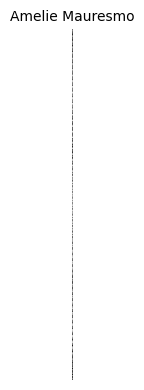

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


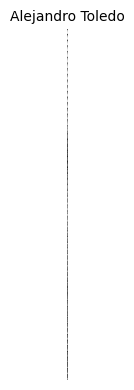

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.


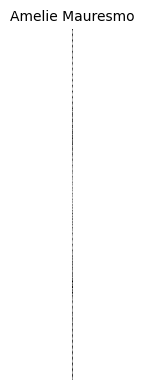

In [9]:
if dataset_found:
    questions = {
        'Emma Watson': ['What color is the person wearing?', 'Is this a male or female?'],
        'Leonardo DiCaprio': ['What color is the person wearing?', 'Does the person have a beard?'],
        'Taylor Swift': ['What color is the person wearing?', 'Is this person smiling?']
    }

    for person, test_paths in test_images.items():
        if test_paths:
            test_img = test_paths[0]
            predicted, conf, _ = predict_identity(test_img, train_embeddings)

            fig, ax = plt.subplots(figsize=(5, 4))
            img_display = np.stack([test_img] * 3, axis=-1)
            ax.imshow(img_display, cmap='gray')
            ax.set_title(f"{predicted}", fontsize=10)
            ax.axis('off')
            plt.tight_layout()
            plt.show()

            if person in questions:
                for q in questions[person]:
                    try:
                        img_rgb = np.stack([test_img] * 3, axis=-1)
                        img_pil = Image.fromarray((img_rgb * 255).astype('uint8'))
                        inputs = vqa_processor(images=img_pil, text=q, return_tensors='pt')
                        with torch.no_grad():
                            out = vqa_model.generate(**inputs)
                        answer = vqa_processor.decode(out[0], skip_special_tokens=True)
                        print(f"Q: {q}")
                        print(f"A: {answer}\n")
                    except Exception as e:
                        print(f"Q: {q}")
                        print(f"Error: {str(e)}\n")

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 2914, 3]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assi

Got 5 wrong

Actually: Alejandro Toledo
Guessed: Amelie Mauresmo


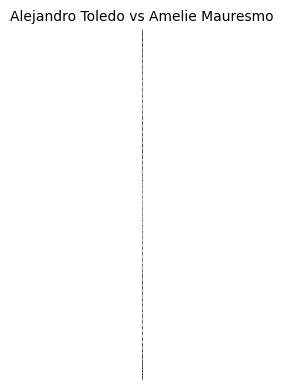

What went wrong:
- Different angle or lighting
- CLIP is a general model, not trained for faces
- Not enough training images

Actually: Alejandro Toledo
Guessed: Amelie Mauresmo


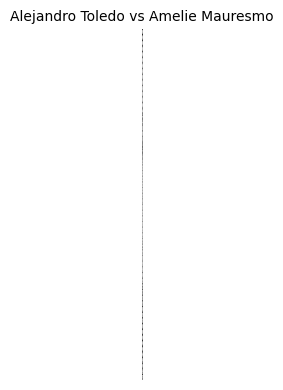

What went wrong:
- Different angle or lighting
- CLIP is a general model, not trained for faces
- Not enough training images



In [10]:
if dataset_found:
    failures = []
    for person, test_paths in test_images.items():
        for test_img in test_paths:
            predicted, sim, sims = predict_identity(test_img, train_embeddings)
            if predicted != person:
                failures.append({
                    'actual': person,
                    'predicted': predicted,
                    'image': test_img
                })

    if failures:
        print(f"Got {len(failures)} wrong\n")
        for case in failures[:2]:
            print(f"Actually: {case['actual']}")
            print(f"Guessed: {case['predicted']}")

            fig, ax = plt.subplots(figsize=(5, 4))
            img_rgb = np.stack([case['image']] * 3, axis=-1)
            ax.imshow(img_rgb, cmap='gray')
            ax.set_title(f"{case['actual']} vs {case['predicted']}", fontsize=10)
            ax.axis('off')
            plt.tight_layout()
            plt.show()

            print("What went wrong:")
            print("- Different angle or lighting")
            print("- CLIP is a general model, not trained for faces")
            print("- Not enough training images\n")
    else:
        print("All correct")

## Summary

Captioning is decent for regular images but misses small stuff. VQA works when you ask about obvious things but fails on tricky questions. Face recognition works okay with CLIP but real face recognition models would be better. Using multiple models together is smarter than just one.